# BIOMASS forest height against LVIS and GEDI — version without the workshop files
## Official L2A forest height, optionally next to an external height map

**ESA MAAP Hackathon 2026 — Challenge #5 "Canopy Clash"** · variant of notebook 02

The original notebook 02 compares the official BIOMASS L2A forest height (FH) with a second product stored in the
BIOMASS-Coding2026 workshop folder on MAAP. If you do not have that folder, this version runs **without it**.

**What it does.**
- Always: the official L2A product against the LVIS airborne LiDAR (accuracy, averaging test, slopes, savanna,
  repeatability, geolocation) and the **whole GEDI chapter** (is GEDI a good referee? what does GEDI say about BIOMASS?).
- Optionally: one **external canopy-height GeoTIFF** that you download yourself (set `ALT_FH_PATH` in the setup cell),
  put through exactly the same tests. It plays the role the workshop mosaic had: one static map, no per-date files.

**What it cannot do without the workshop files.** The per-date comparisons of the second product (its slope behaviour per
orbit direction, its repeatability between dates, the date-pairing table and the footprint map) need one file per
acquisition, so they are left out.

| Question | Test |
|---|---|
| 1. Pixel by pixel, how close is each product to the LiDAR? | accuracy by landscape stratum (Chapter 3) |
| 2. Are the errors random or systematic? | averaging test (Chapter 4) |
| 3. Does L2A fail on slopes facing the radar? | error vs local incidence angle (Chapter 5) |
| 4. And on savanna? | short-vegetation test (Chapter 6) |
| 5. Do two L2A dates agree? | repeatability (Chapter 7) |
| 6. Is it in the right place? | geolocation check (Chapter 8) |
| 7. **What does GEDI say, and can GEDI be trusted as referee?** | **GEDI vs LVIS, BIOMASS vs GEDI (Chapter 9)** |

## 1 — The products

| | Official L2A FH | External map (optional) |
|---|---|---|
| Where | ESA MAAP STAC catalogue, processor 4.4.4 | a GeoTIFF you provide through `ALT_FH_PATH` |
| One file per | stack of acquisitions of one track (INT phase) | one static map (one or more tiles) |
| Metadata | orbit, track, footprint, quality layer, forest mask | none needed: only height in metres |

The external map is read **only inside each site box**, reprojected onto the same grid as notebook 01 and **averaged**
(not sub-sampled) when its pixels are smaller than the grid, so every pixel is compared with the same LiDAR pixel.

**Read this before interpreting the external map.**
- Most global canopy-height maps (for example the ETH 10 m map for 2020, or the Meta/WRI map) were **trained on GEDI**.
  Against GEDI they will look better than they are: use LVIS as the main referee for them.
- They describe a different year (2020 or so) from BIOMASS (2026) and from LVIS (2016).
- They have no viewing geometry, so slope tests per orbit direction do not apply to them.

In [1]:
# Setup
import importlib.util, subprocess, sys, json, os, warnings
from pathlib import Path
if importlib.util.find_spec("pptx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-pptx"], check=True)

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle, Polygon
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = next((c for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (c / "src" / "__init__.py").exists() and (c / "config" / "sites.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the topic folder (it needs src/ and config/).")
sys.path.insert(0, str(ROOT)); importlib.invalidate_caches()
from src.load.workshop import to_grid  # not used any more, kept so the src package imports unchanged
import glob
from rasterio.warp import Resampling, reproject, transform_bounds
from rasterio.windows import Window, from_bounds
from rasterio.errors import WindowError
from src.process.site import load_site, mosaic_site
from src.process.aggregate import at_scale, gedi_blocks, best_gedi
from src.evaluate import accuracy as acc
from src.evaluate.multiscale import scale_curve, best_shift, block_comparison

CFG = json.loads((ROOT / "config" / "sites.json").read_text()); SITES = CFG["sites"]
# Optional external canopy-height GeoTIFF (metres). A path, or a pattern such as "data/ext/*.tif" for several tiles.
# Leave empty to run with the official L2A product only. Can also be set with the ALT_FH_PATH environment variable.
ALT_FH_PATH = os.environ.get("ALT_FH_PATH", "")
ALT_NAME = "External"
FIG = ROOT / "results" / "no_workshop_fh"; FIG.mkdir(parents=True, exist_ok=True)
C_L2A, C_WS, C_MOS, C_LVIS = "#2a78d6", "#c2457a", "#7a2048", "#eb6834"
C_ASC, C_DESC = "#6250d6", "#eda100"
PRODUCTS = {"L2A": C_L2A, ALT_NAME: C_WS}
HEIGHT_CMAP = LinearSegmentedColormap.from_list("height", ["#f4f1e6", "#9fcf8f", "#2e8b3e", "#0b3d1f"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
FACTS, FIGS = {}, {}

def savefig(fig, name):
    p = FIG / f"{name}.png"; fig.savefig(p, dpi=150, bbox_inches="tight", facecolor="white"); FIGS[name] = p; return p

print("Project:", ROOT)
print("External map:", ALT_FH_PATH or "none (L2A only)")

Project: /home/alexia/biomass2026/biomass-hackathon-2026/topics/05_BIOMASS_AND_GEDI/forestheight
External map: none (L2A only)


In [2]:
# Every product on the same grid as notebook 01 (the LiDAR grid of each site)
kw = dict(swath_incidence=tuple(CFG["swath_incidence_deg"]), min_coverage=CFG["lvis_min_coverage_fraction"],
          min_pass_coverage=CFG.get("min_pass_lidar_coverage", 0.2))
D = {k: load_site(k, s, ROOT, **kw) for k, s in SITES.items()}                                     # official L2A
KEYS = list(D)

def alt_on_grid(path, S, pad=0.02, max_height=100.0):
    """Read only the part of 'path' that covers the site box, average it onto the site grid. NaN where there is no data."""
    out = np.full(S["grid"].shape, np.nan, "float32")
    W_, S_, E_, N_ = S["bbox"]
    with rasterio.open(path) as src:
        crs = src.crs or "EPSG:4326"
        l, b, r, t = transform_bounds("EPSG:4326", crs, W_ - pad, S_ - pad, E_ + pad, N_ + pad)
        try:
            win = from_bounds(l, b, r, t, src.transform).round_offsets().round_lengths()
            win = win.intersection(Window(0, 0, src.width, src.height))
        except WindowError:
            return out                                   # this tile does not touch the site
        a = src.read(1, window=win).astype("float32"); tr = src.window_transform(win); nod = src.nodata
    if nod is not None:
        a[a == nod] = np.nan
    a[(a < 0) | (a > max_height)] = np.nan               # also catches 255-style fill values
    reproject(a, out, src_transform=tr, src_crs=crs, dst_transform=S["grid"].transform, dst_crs=S["grid"].crs,
              resampling=Resampling.average, src_nodata=np.nan, dst_nodata=np.nan)
    return out

ALT_FILES = sorted(glob.glob(str(Path(ALT_FH_PATH).expanduser()))) if ALT_FH_PATH else []
if ALT_FH_PATH and not ALT_FILES:
    print(f"WARNING: nothing found at ALT_FH_PATH={ALT_FH_PATH!r}: running with the official L2A product only.")
A = {}
for k, S in D.items():
    h = np.full(S["grid"].shape, np.nan, "float32")
    for f in ALT_FILES:
        h = np.where(np.isfinite(h), h, alt_on_grid(f, S))
    if np.isfinite(h).any():
        A[k] = mosaic_site(S, h)
    elif ALT_FILES:
        print(f"{S['name']}: the external map has no valid pixel inside the site box, site skipped for that product.")
A = A if len(A) == len(D) else {}                          # all three sites or none: keeps every table comparable
PROD = {"L2A": D, **({ALT_NAME: A} if A else {})}
PRODUCTS = {n: c for n, c in PRODUCTS.items() if n in PROD}
OTHER = [n for n in PROD if n != "L2A"]
print("Products compared:", list(PROD))

Rabi: 8 frames -> 6 passes, 3 kept (>= 20% of the LiDAR area); best: 28 Jul desc T011
Rabi: grid (733, 818), 3 BIOMASS passes, LVIS yes, GEDI shots 82,854
Mabounie: 9 frames -> 8 passes, 3 kept (>= 20% of the LiDAR area); best: 26 Apr asce T003
Mabounie: grid (326, 969), 3 BIOMASS passes, LVIS yes, GEDI shots 48,350
Lopé: 8 frames -> 7 passes, 1 kept (>= 20% of the LiDAR area); best: 15 Dec asce T004
Lopé: grid (752, 753), 1 BIOMASS passes, LVIS yes, GEDI shots 198,595
Products compared: ['L2A']


## 2 — First look

Same colour scale (0–60 m) and same window as notebook 01. Left to right: the LiDAR reference, the official product and,
if you provided one, the external map.

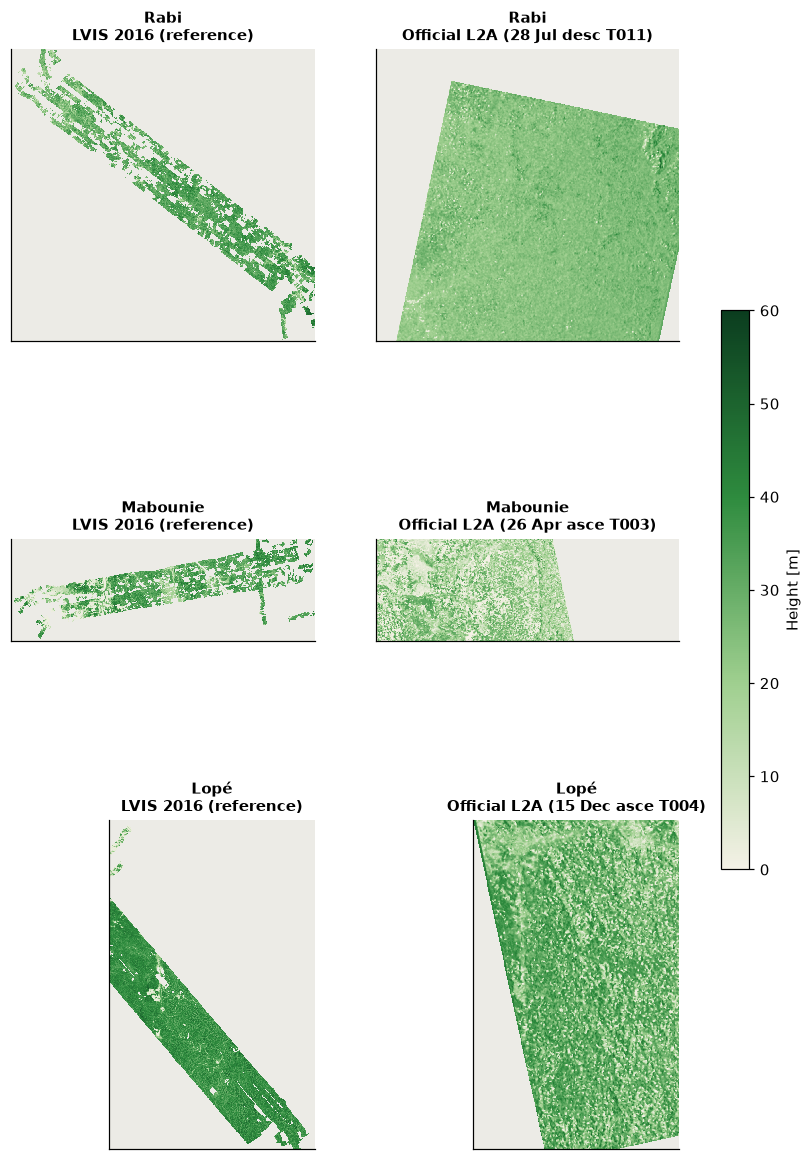

In [3]:
fig, ax = plt.subplots(len(KEYS), 2 + len(OTHER), figsize=(4.4 * (2 + len(OTHER)) + 1, 4.4 * len(KEYS)), squeeze=False)
norm = Normalize(0, 60)
for i, k in enumerate(KEYS):
    S = D[k]; win, ext = S["win"], S["win_extent"]
    panels = [(S["lvis"], "LVIS 2016 (reference)"),
              (S["best"]["h"] if S["best"] else None, f"Official L2A ({S['best']['label']})" if S["best"] else "L2A: none")]
    panels += [(PROD[n][k]["best"]["h"], n) for n in OTHER]
    for j, (arr, title) in enumerate(panels):
        a = ax[i, j]; a.set_facecolor("#ecebe6")
        if arr is not None:
            im = a.imshow(arr[win], extent=ext, cmap=HEIGHT_CMAP, norm=norm, interpolation="nearest")
        a.set_title(f"{S['name']}\n{title}", fontsize=9.5); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, shrink=.5, label="Height [m]")
savefig(fig, "02_first_look"); plt.show()

The histograms below show how wide the distribution of heights is for each product, compared with the LiDAR.

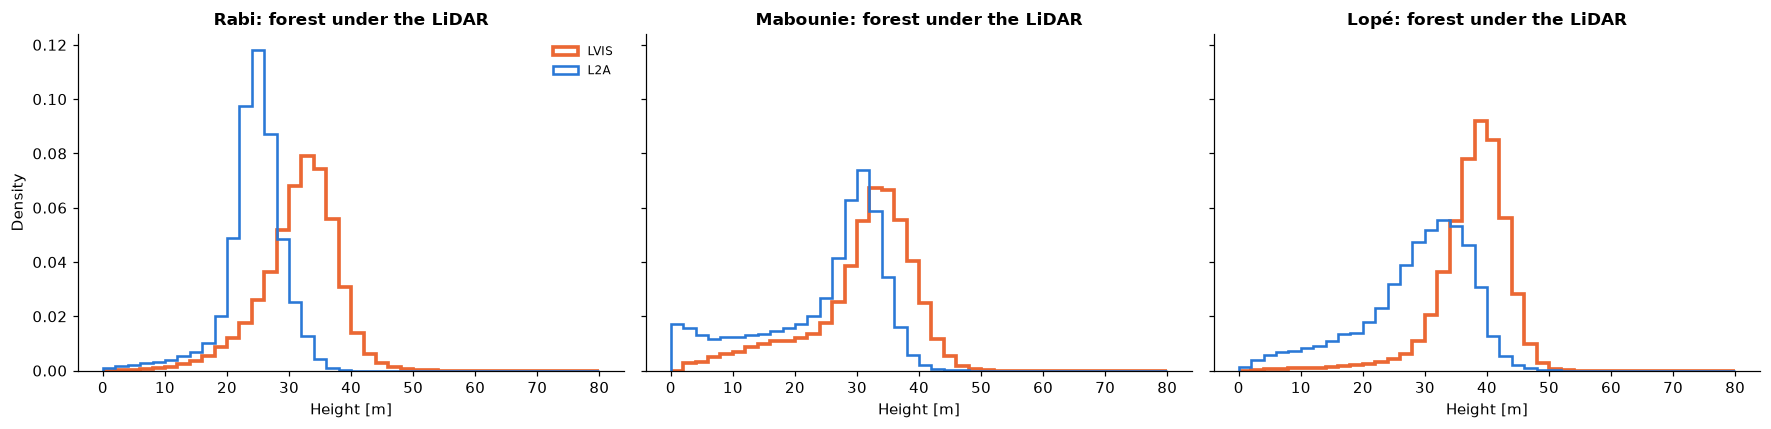

,site,product,p5,median,p95,p95 − p5
0,Rabi,LVIS,20.3,32.4,40.0,19.8
1,Rabi,L2A,15.6,24.8,31.3,15.7
2,Mabounie,LVIS,12.1,32.7,41.4,29.3
3,Mabounie,L2A,3.0,28.2,36.0,33.0
4,Lopé,LVIS,28.1,38.5,45.0,16.9
5,Lopé,L2A,10.0,30.4,39.7,29.7


In [4]:
bins = np.arange(0, 82, 2)
fig, ax = plt.subplots(1, len(KEYS), figsize=(5.4 * len(KEYS), 4), sharey=True, squeeze=False)
rows = []
for a, k in zip(ax[0], KEYS):
    S = D[k]; m = (S["cover"] == acc.FOREST) & np.isfinite(S["lvis"])
    a.hist(S["lvis"][m], bins, density=True, histtype="step", lw=2.4, color=C_LVIS, label="LVIS")
    rows.append({"site": S["name"], "product": "LVIS", **dict(zip(["p5", "median", "p95"], np.nanpercentile(S["lvis"][m], [5, 50, 95])))})
    for name, P in PROD.items():
        if not P[k]["scenes"]:
            continue
        v = np.concatenate([p["h"][m] for p in P[k]["scenes"]]); v = v[np.isfinite(v)]
        a.hist(v, bins, density=True, histtype="step", lw=1.7, color=PRODUCTS[name], label=name)
        rows.append({"site": S["name"], "product": name, **dict(zip(["p5", "median", "p95"], np.percentile(v, [5, 50, 95])))})
    a.set(title=f"{S['name']}: forest under the LiDAR", xlabel="Height [m]")
ax[0, 0].set_ylabel("Density"); ax[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "03_histograms"); plt.show()
SPREAD = pd.DataFrame(rows); SPREAD["p95 − p5"] = SPREAD.p95 - SPREAD.p5
display(SPREAD.round(1))

**How to read the histograms.** A product whose histogram is much *narrower* than the LiDAR one compresses the heights
(tall forest comes out too low); one that is much *wider* is noisy, with unrealistic very low or very high pixels.
The table gives the 5th, 50th and 95th percentiles and their spread. In the original run the official L2A was too narrow
(a few metres around 28–35 m).

## 3 — Pixel by pixel: which product is closer to the LiDAR?

Same strata as notebook 01. Errors are **product − LVIS** (negative = too low); median over the passes of each site.

rmse   bias     r
product                              L2A    L2A   L2A
site     stratum                                     
Rabi     all                        9.41  -5.47  0.24
         forest, flat (<5°)         8.26  -3.97  0.29
         forest, moderate (5–15°)   9.63  -6.15  0.18
         forest, steep (≥15°)      11.81  -8.99  0.06
         savanna                   18.59  17.45 -0.22
Mabounie all                        8.55  -3.15  0.38
         forest, flat (<5°)         7.71  -0.79  0.60
         forest, moderate (5–15°)   8.23  -3.46  0.30
         forest, steep (≥15°)      10.82  -5.56  0.10
         savanna                   10.55   7.67  0.00
Lopé     all                       13.51  -8.43  0.12
         forest, flat (<5°)        10.48  -5.37  0.26
         forest, moderate (5–15°)  12.80  -8.65  0.09
         forest, steep (≥15°)      14.78 -10.71  0.09
         savanna                   20.32  18.06  0.04

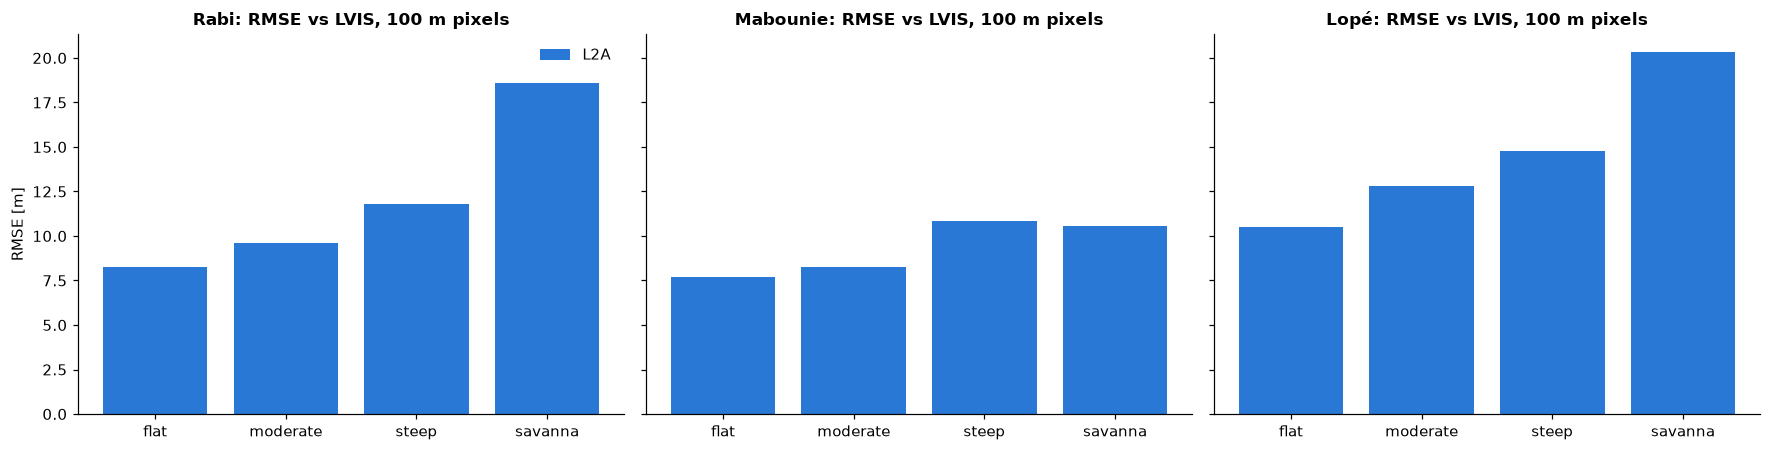

In [5]:
ACC = {name: acc.accuracy_table(list(P.values())) for name, P in PROD.items()}
SUM = pd.concat([acc.site_summary(a, "LVIS").assign(product=name) for name, a in ACC.items()], ignore_index=True)
SUM.to_csv(FIG / "accuracy_by_stratum_100m.csv", index=False)
display(SUM.pivot_table(index=["site", "stratum"], columns="product", values=["rmse", "bias", "r"], sort=False).round(2))

order = ["forest, flat (<5°)", "forest, moderate (5–15°)", "forest, steep (≥15°)", "savanna"]
fig, ax = plt.subplots(1, len(KEYS), figsize=(5.4 * len(KEYS), 4.2), sharey=True, squeeze=False)
x = np.arange(len(order)); wb = .8 / len(PRODUCTS)
for a, k in zip(ax[0], KEYS):
    for i, (name, c) in enumerate(PRODUCTS.items()):
        t = SUM[(SUM["product"] == name) & (SUM.site == D[k]["name"])].set_index("stratum").reindex(order)
        a.bar(x + (i - (len(PRODUCTS) - 1) / 2) * wb, t.rmse, wb, color=c, label=name)
    a.set_xticks(x, ["flat", "moderate", "steep", "savanna"])
    a.set_title(f"{D[k]['name']}: RMSE vs LVIS, 100 m pixels")
ax[0, 0].set_ylabel("RMSE [m]"); ax[0, 0].legend(frameon=False)
fig.tight_layout(); savefig(fig, "04_rmse_by_stratum"); plt.show()

RMSE mixes two things: a **systematic** part (the bias, always the same direction) and a **random** part (the noise,
different for every pixel). They behave very differently when we look at the forest at a coarser scale, which is the
next test.

## 4 — Noise or bias? The averaging test

We average both the product **and** the LiDAR over windows of 3×3, 5×5, 9×9 and 15×15 pixels (about 300 m to 1.4 km) and recompute the forest error.
- **Random noise** averages out: the RMSE falls quickly with the window.
- **Systematic error** does not average out: it stays as it is.

Since RMSE² = bias² + SD², the bottom row shows the systematic part alone.

rmse  bias
product            L2A   L2A
site     size_m             
Rabi     90       9.40 -5.50
         280      8.11 -5.53
         460      7.37 -5.53
         840      6.60 -5.51
         1390     6.15 -5.51
Mabounie 90       8.48 -3.26
         280      7.30 -3.26
         460      6.63 -3.25
         840      5.86 -3.20
         1390     5.32 -3.12
Lopé     90      13.40 -9.22
         280     12.01 -9.06
         460     11.17 -8.98
         840     10.34 -8.92
         1390     9.90 -8.89

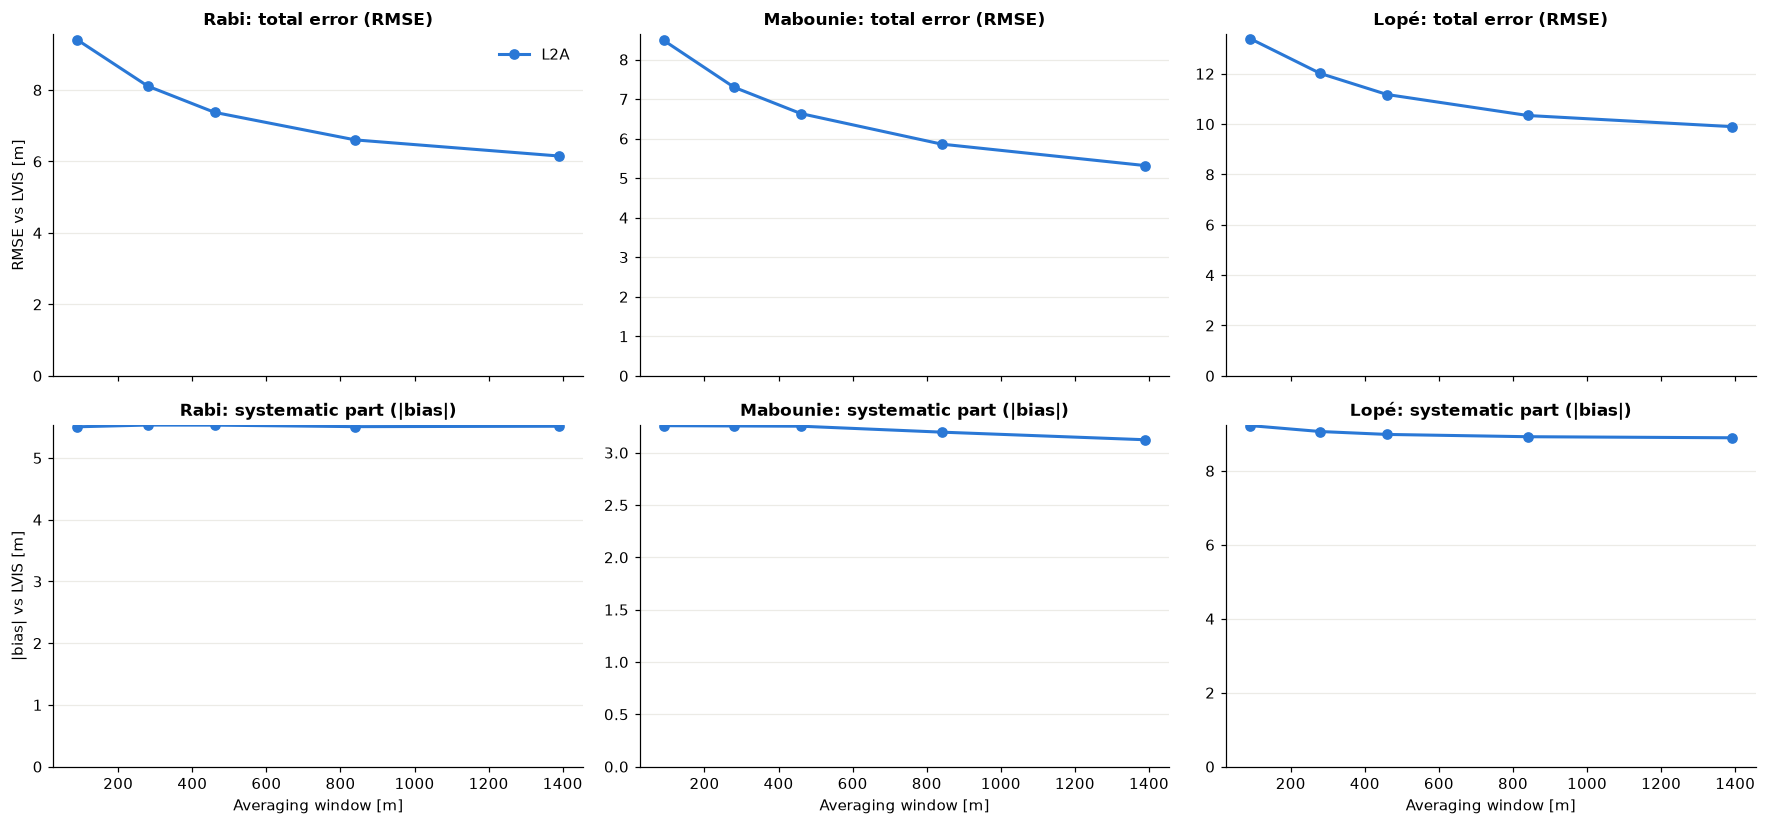

In [6]:
SCALE = pd.concat([scale_curve(P[k], name) for k in KEYS for name, P in PROD.items()], ignore_index=True)
SCALE.to_csv(FIG / "error_vs_scale.csv", index=False)
display(SCALE.pivot_table(index=["site", "size_m"], columns="product", values=["rmse", "bias"], sort=False).round(2))
fig, ax = plt.subplots(2, len(KEYS), figsize=(5.4 * len(KEYS), 7.6), sharex=True, squeeze=False)
for j, k in enumerate(KEYS):
    t = SCALE[SCALE.site == D[k]["name"]]
    for name, c in PRODUCTS.items():
        u = t[t["product"] == name]
        ax[0, j].plot(u.size_m, u.rmse, "o-", color=c, lw=2, label=name)
        ax[1, j].plot(u.size_m, u.bias.abs(), "o-", color=c, lw=2, label=name)
    ax[0, j].set_title(f"{D[k]['name']}: total error (RMSE)"); ax[1, j].set_title(f"{D[k]['name']}: systematic part (|bias|)")
    ax[1, j].set_xlabel("Averaging window [m]")
    for a in ax[:, j]:
        a.set_ylim(0, None); a.grid(axis="y", color="#ecebe6")
ax[0, 0].set_ylabel("RMSE vs LVIS [m]"); ax[1, 0].set_ylabel("|bias| vs LVIS [m]"); ax[0, 0].legend(frameon=False)
fig.tight_layout(); savefig(fig, "05_error_vs_scale"); plt.show()

In [7]:
# Compare again by stratum, at about 500 m (5 x 5 pixels), the scale where the two curves meet
K = 5
SUM5 = pd.concat([acc.site_summary(acc.accuracy_table([at_scale(P[k], K) for k in KEYS]), "LVIS").assign(product=name)
                  for name, P in PROD.items()], ignore_index=True)
SUM5.to_csv(FIG / "accuracy_by_stratum_500m.csv", index=False)
display(SUM5.pivot_table(index=["site", "stratum"], columns="product", values=["rmse", "bias", "r"], sort=False).round(2))

rmse   bias     r
product                              L2A    L2A   L2A
site     stratum                                     
Rabi     all                        7.37  -5.52  0.34
         forest, flat (<5°)         6.61  -4.50  0.37
         forest, moderate (5–15°)   7.66  -5.96  0.32
         forest, steep (≥15°)       9.17  -7.40  0.19
         savanna                    7.95   3.28 -0.11
Mabounie all                        6.65  -3.19  0.51
         forest, flat (<5°)         5.98  -1.56  0.69
         forest, moderate (5–15°)   6.52  -3.49  0.43
         forest, steep (≥15°)       8.03  -4.68  0.23
         savanna                    7.81   3.64  0.17
Lopé     all                       11.16  -8.46  0.15
         forest, flat (<5°)         8.67  -5.31  0.25
         forest, moderate (5–15°)  10.63  -8.46  0.09
         forest, steep (≥15°)      12.40 -10.36  0.08
         savanna                   13.92  11.02  0.10

**How to read the averaging test.**
- A curve that **falls steeply** with the window is dominated by random noise, which averaging removes.
- A **flat** curve means the error is mostly systematic (compression, slope bias, a different year), which averaging cannot remove.
- The bottom row shows the systematic part alone (|bias|), since RMSE² = bias² + SD².

In the original run the official L2A curve was flat (mostly systematic error), so averaging did not help it.

## 5 — Slopes: does L2A suffer from foreshortening?

Notebook 01 found that the official product is **10–20 m too low** where the slope faces the radar (small local incidence
angle). This test needs the viewing geometry of every pass, so it is run for the official L2A only (the external map has
none).

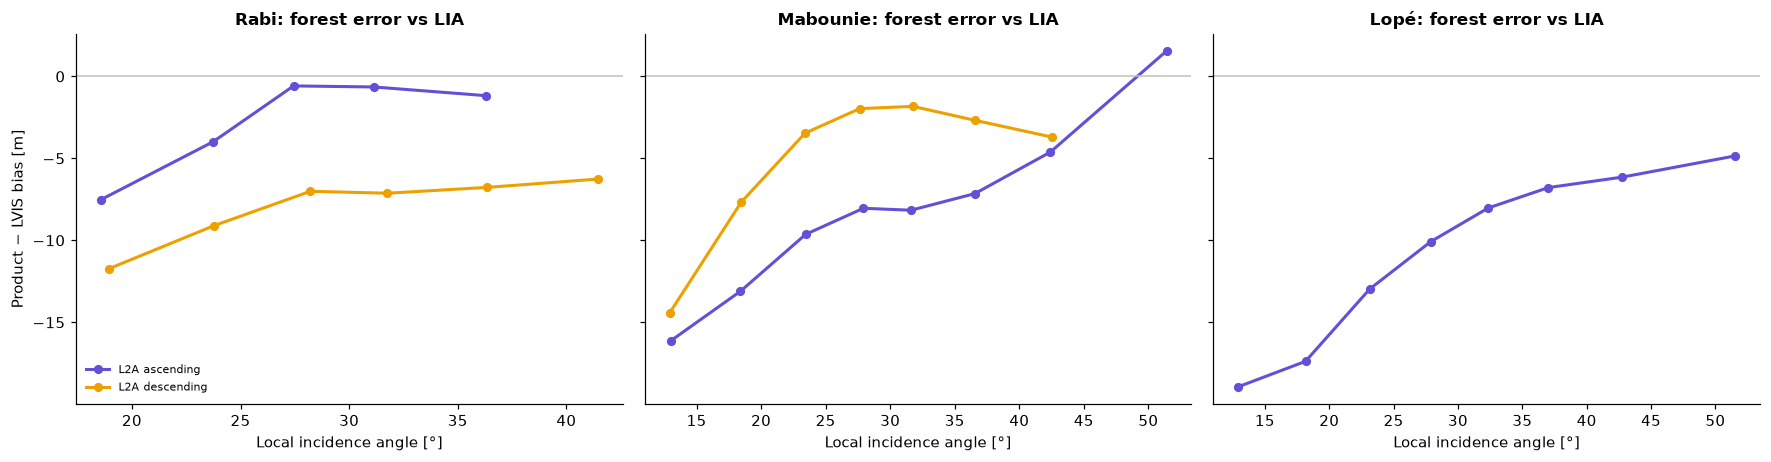

,product,site,orbit,facing_radar,radar_flat,facing_away,facing radar − flat [m],facing away − flat [m],total swing [m]
0,L2A,Lopé,ascending,-17.8,-9.0,-6.1,-8.8,2.9,11.7
1,L2A,Mabounie,ascending,-13.7,-8.1,-4.4,-5.6,3.6,9.3
2,L2A,Mabounie,descending,-8.8,-1.9,-3.7,-6.9,-1.8,5.1
3,L2A,Rabi,ascending,-7.5,-0.6,NaN,-6.9,NaN,NaN
4,L2A,Rabi,descending,-11.7,-7.1,-6.3,-4.7,0.8,5.5


In [8]:
LIA = pd.concat([pd.DataFrame()] + [acc.error_vs_lia(P[k]).assign(product=name)
                                    for k in KEYS for name, P in [("L2A", D)] if P[k]["scenes"] and P[k]["lvis"] is not None],
                ignore_index=True)
LIA.to_csv(FIG / "error_vs_lia.csv", index=False)
fig, ax = plt.subplots(1, len(KEYS), figsize=(5.4 * len(KEYS), 4.3), sharey=True, squeeze=False)
for a, k in zip(ax[0], KEYS):
    t = LIA[LIA.site == D[k]["name"]]
    for (prod, ls, mk) in [("L2A", "-", "o")]:
        for orb, c in [("ascending", C_ASC), ("descending", C_DESC)]:
            u = t[(t["product"] == prod) & (t.orbit == orb)]
            if len(u):
                a.plot(u.lia_mid, u.bias, ls=ls, marker=mk, color=c, lw=2, ms=5, label=f"{prod} {orb}")
    a.axhline(0, color="#c3c2b7", lw=1)
    a.set(title=f"{D[k]['name']}: forest error vs LIA", xlabel="Local incidence angle [°]")
ax[0, 0].set_ylabel("Product − LVIS bias [m]"); ax[0, 0].legend(frameon=False, fontsize=7.5)
fig.tight_layout(); savefig(fig, "06_error_vs_lia"); plt.show()

rows = []
for (prod, site, orb), t in LIA.groupby(["product", "site", "orbit"]):
    low = t[t.lia_mid < 20]; mid = t[(t.lia_mid >= 25) & (t.lia_mid < 35)]; high = t[t.lia_mid >= 40]
    if len(low) and len(mid):
        rows.append(dict(product=prod, site=site, orbit=orb,
                         facing_radar=np.average(low.bias, weights=low.n), radar_flat=np.average(mid.bias, weights=mid.n),
                         facing_away=np.average(high.bias, weights=high.n) if len(high) else np.nan))
TERRAIN = pd.DataFrame(rows)
if len(TERRAIN):
    TERRAIN["facing radar − flat [m]"] = TERRAIN.facing_radar - TERRAIN.radar_flat
    TERRAIN["facing away − flat [m]"] = TERRAIN.facing_away - TERRAIN.radar_flat
    TERRAIN["total swing [m]"] = TERRAIN.facing_away - TERRAIN.facing_radar
display(TERRAIN.round(1))


**How to read it.** The table summarises each curve with three numbers, all relative to terrain that looks flat to the radar (LIA 25–35°):
- **facing radar − flat**: extra error on slopes facing the radar (LIA < 20°). Negative = too low (foreshortening).
- **facing away − flat**: extra error on slopes facing away (LIA ≥ 40°).
- **total swing**: how much the error changes from one side of a hill to the other. Zero would mean the product ignores the viewing geometry.

## 6 — Savanna: does it see short vegetation?

Same test as notebook 01: vegetation below 10 m. *Recall* = share of truly short pixels (LiDAR) that the product also calls short; *precision* = share of the product's "short" pixels that are truly short.

In [9]:
SV = pd.concat([pd.DataFrame()] + [acc.short_vegetation(P[k], CFG["low_height_m"]).assign(product=name) for k in KEYS for name, P in PROD.items()],
               ignore_index=True)
SV.to_csv(FIG / "short_vegetation.csv", index=False)
display(SV.pivot_table(index=["site", "cover"], columns="product",
                       values=["pixels", "lvis_median", "biomass_median", "recall", "precision"], sort=False).round(1))

pixels lvis_median biomass_median recall precision
product               L2A         L2A            L2A    L2A       L2A
site     cover                                                       
Rabi     forest   20130.0        28.6           24.7    0.5       0.4
         mosaic     211.5        14.9           23.0    8.8      58.3
         savanna     44.0         5.6           23.3    0.0       0.0
Mabounie forest   41562.0        33.0           30.0   45.2       8.3
         mosaic     391.0        19.9           21.8   38.1      59.3
         savanna   1598.0         2.6            9.2   53.9      97.6
Lopé     forest   45577.0        38.2           30.4   12.3       0.3
         mosaic     918.0        21.5           28.3    2.9       8.7
         savanna    768.0         3.5           21.4    5.1      97.3

In this table "biomass_median" is the median height of **the product in that column** (L2A or the external map). Look at the savanna rows: the LiDAR says 3–6 m. Watch the pixel counts too. A product that leaves savanna pixels empty (masked) cannot be wrong there, but it also says nothing about them.

## 7 — Do two dates agree?

The official L2A product is compared **with itself** on forest pixels, for every pair of dates, at 100 m and at 500 m. It has
several passes on the same track. (The external map is a single static map, so it has no repeat to test.)

In [10]:
def rep(P, k, scale=1):
    S = P[k] if scale == 1 else at_scale(P[k], scale)
    if len(S["scenes"]) < 2:
        return pd.DataFrame()
    return acc.repeatability(S, mask=(D[k]["cover"] == acc.FOREST))

REP = pd.concat([pd.DataFrame()] + [rep(P, k, s).assign(product=name, scale=f"{s * 100} m")
                                    for k in KEYS for name, P in [("L2A", D)] for s in (1, 5)], ignore_index=True)
REP["geometry"] = REP.geometry.replace({"same track": "same direction"})
REP = REP[REP.n >= 1000]
REP.to_csv(FIG / "repeatability.csv", index=False)
display(REP[REP.scale == "100 m"][["product", "site", "a", "b", "days", "geometry", "n", "bias", "rmse", "r"]].round(2))
REP_SUM = REP.groupby(["product", "scale", "geometry"]).agg(pairs=("rmse", "size"), median_rmse=("rmse", "median"),
                                                          median_r=("r", "median")).reset_index()
display(REP_SUM.round(2))

,product,site,a,b,days,geometry,n,bias,rmse,r
0,L2A,Rabi,07 Jun asce T003,07 Jul desc T011,30.0,opposite directions,164264.0,-5.36,10.24,0.36
1,L2A,Rabi,07 Jun asce T003,28 Jul desc T011,51.0,opposite directions,90321.0,-6.03,9.67,0.06
2,L2A,Rabi,07 Jul desc T011,28 Jul desc T011,21.0,same direction,84554.0,-1.85,7.66,0.25
6,L2A,Mabounie,27 Mar asce T003,26 Apr asce T003,30.0,same direction,62610.0,-11.08,16.29,0.10
7,L2A,Mabounie,27 Mar asce T003,18 Aug desc T011,144.0,opposite directions,123633.0,1.62,7.92,0.18
8,L2A,Mabounie,26 Apr asce T003,18 Aug desc T011,114.0,opposite directions,12206.0,11.22,15.19,-0.09


,product,scale,geometry,pairs,median_rmse,median_r
0,L2A,100 m,opposite directions,4,9.95,0.12
1,L2A,100 m,same direction,2,11.98,0.18
2,L2A,500 m,opposite directions,4,8.12,0.25
3,L2A,500 m,same direction,2,10.04,0.22


## 8 — Is it in the right place? (geolocation check)

We shift each map by up to ±5 pixels (≈ ±500 m) and look for the shift that best matches the LiDAR. A well-geolocated product gives its best match at zero shift; a shift of one pixel is within the noise.

In [11]:
rows = []
for k in KEYS:
    S = D[k]; m = S["cover"] == acc.FOREST
    for name, P in PROD.items():
        if P[k]["best"] is None or S["lvis"] is None:
            continue
        r = best_shift(P[k]["best"]["h"], S["lvis"], m)
        rows.append({"site": S["name"], "product": name, "pass": P[k]["best"]["label"], **r,
                     "shift [m]": int(round(np.hypot(r["shift_rows"], r["shift_cols"]) * S["grid"].res * 111320, -1))})
GEO = pd.DataFrame(rows); GEO.to_csv(FIG / "geolocation.csv", index=False)
display(GEO.round(3))

,site,product,pass,r_at_zero,r_best,shift_rows,shift_cols,shift [m]
0,Rabi,L2A,28 Jul desc T011,0.215,0.271,-1,-3,290
1,Mabounie,L2A,26 Apr asce T003,0.064,0.092,-1,2,210
2,Lopé,L2A,15 Dec asce T004,0.089,0.098,-1,-1,130


**How to read it.** A shift of one pixel (≈ 90–130 m) is within the noise of this test. In the original run the only larger
shift was the official Mabounie pass (≈ 290 m, correlation 0.40 → 0.50): a single pass, so a lead to check, not a conclusion.

## 9 — And GEDI? The comparison the challenge asks for

Up to now the referee was the airborne LiDAR. But LVIS exists only on a few strips flown in 2016. Almost everywhere else, the only independent canopy height is **GEDI**, the LiDAR on the International Space Station (2019–2025). So the real questions of the challenge are:
- **(a)** Is GEDI a good referee? We check it against LVIS.
- **(b)** What does BIOMASS look like against GEDI, and does GEDI give the same verdict as LVIS?
- **(c)** Do the results hold **outside** the LiDAR strips, where only GEDI exists?

**How we compare.** A GEDI shot is a 25 m footprint, and the shots lie along tracks, so a 100 m pixel usually contains one shot at most. Single-pixel comparisons are therefore very noisy. We compare **blocks of k×k pixels** (from 100 m to ≈ 1 km):
- product = mean of the block;
- LVIS = mean of the block;
- GEDI = median of the shots in the block (at least 3 shots for blocks larger than one pixel).

Forest blocks only (≥ 80% forest). The GEDI shots were already filtered at download: quality_flag = 1, degrade_flag = 0, sensitivity ≥ 0.95.

In [12]:
C_GEDI = "#1baf7a"
BC = block_comparison(D, PROD)
BC.to_csv(FIG / "gedi_block_comparison.csv", index=False)
print(f"{len(BC)} rows; block sizes: {sorted(BC.size_m.unique())} m")

60 rows; block sizes: [np.int64(90), np.int64(280), np.int64(460), np.int64(930)] m


### 9a — Is GEDI a good referee?

n                         bias  \
size_m                                  90      280     460    930   90    
site     estimate                                                          
Rabi     GEDI (all shots)            6373.0  1543.0  1122.0  443.0 -4.87   
         GEDI (power beams, night)   2640.0   663.0   488.0  217.0 -3.78   
Mabounie GEDI (all shots)            8636.0  2177.0  1398.0  492.0 -4.65   
         GEDI (power beams, night)   2376.0   621.0   494.0  202.0 -1.97   
Lopé     GEDI (all shots)           21328.0  4564.0  2585.0  801.0 -5.66   
         GEDI (power beams, night)   9298.0  2146.0  1444.0  538.0 -2.92   

                                                       rmse                    
size_m                               280   460   930    90    280   460   930  
site     estimate                                                              
Rabi     GEDI (all shots)          -4.77 -5.01 -5.56  10.08  7.82  8.17  7.90  
         GEDI (power beams, night) -3.72 -3.51 -4.23   9.19  6.44  7.59  7.23  
Mabounie GEDI (all shots)          -4.40 -4.56 -4.96   9.96  8.08  8.69  8.11  
         GEDI (power beams, night) -1.98 -1.62 -2.19   9.22  7.81  9.17  8.14  
Lopé     GEDI (all shots)          -5.84 -6.14 -6.28  11.49  9.49  9.30  9.02  
         GEDI (power beams, night) -2.94 -3.45 -3.74  10.19  7.83  7.91  8.29

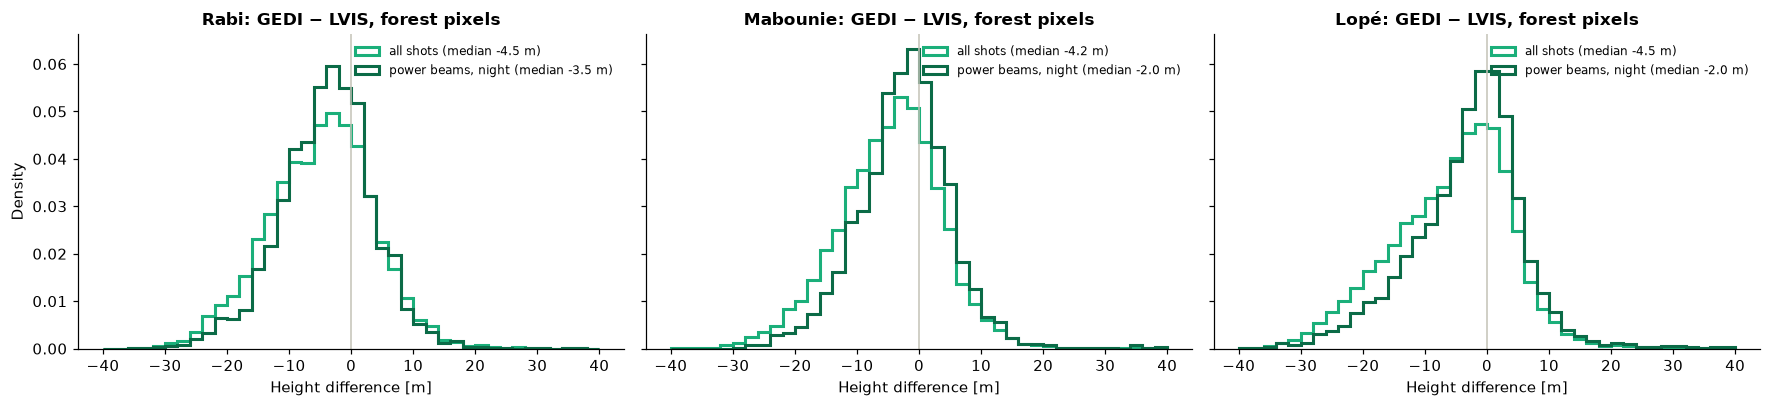

In [13]:
display(BC[BC.reference.eq("LVIS") & BC.estimate.str.startswith("GEDI")]
        .pivot_table(index=["site", "estimate"], columns="size_m", values=["n", "bias", "rmse"], sort=False).round(2))
fig, ax = plt.subplots(1, len(KEYS), figsize=(5.4 * len(KEYS), 3.8), sharey=True, squeeze=False)
bins = np.arange(-40, 41, 2)
for a, k in zip(ax[0], KEYS):
    S = D[k]; f = (S["cover"] == acc.FOREST) & np.isfinite(S["lvis"])
    for shots, lab, c in ((S["gedi_shots"], "all shots", C_GEDI), (best_gedi(S["gedi_shots"]), "power beams, night", "#0b6b47")):
        G, _ = gedi_blocks(S, 1, shots)
        d = (G - S["lvis"])[f & np.isfinite(G)]
        a.hist(d, bins, density=True, histtype="step", lw=2, color=c, label=f"{lab} (median {np.median(d):+.1f} m)")
    a.axvline(0, color="#c3c2b7", lw=1)
    a.set(title=f"{S['name']}: GEDI − LVIS, forest pixels", xlabel="Height difference [m]")
    a.legend(frameon=False, fontsize=8)
ax[0, 0].set_ylabel("Density")
fig.tight_layout(); savefig(fig, "08_gedi_vs_lvis"); plt.show()

**Reading it.**
- **GEDI is lower than LVIS** by about 2–5 m in these forests. Part of it is GEDI itself: in tall, dense tropical canopy the weak echo from the top is easy to miss. Part is time: LVIS is from 2016, GEDI from 2019–2025. The **power beams at night**, which penetrate best, reduce the gap a lot.
- **Per pixel the scatter is large** (8–10 m RMSE) and it stays at 5–8 m even over ≈ 1 km blocks. GEDI's geolocation (≈ 10 m), its small footprint and real forest change since 2016 all contribute.

So GEDI is a **good referee for averages over many shots, a noisy one for single pixels, and it sits a few metres low**. Everything BIOMASS is compared with in the next step inherits this.

### 9b — BIOMASS against GEDI, next to BIOMASS against LVIS

Same blocks, inside the LiDAR area, so both referees judge the same forest. **Solid lines**: against LVIS. **Dashed lines**: against GEDI. **Dotted green**: GEDI against LVIS (the referee's own error).

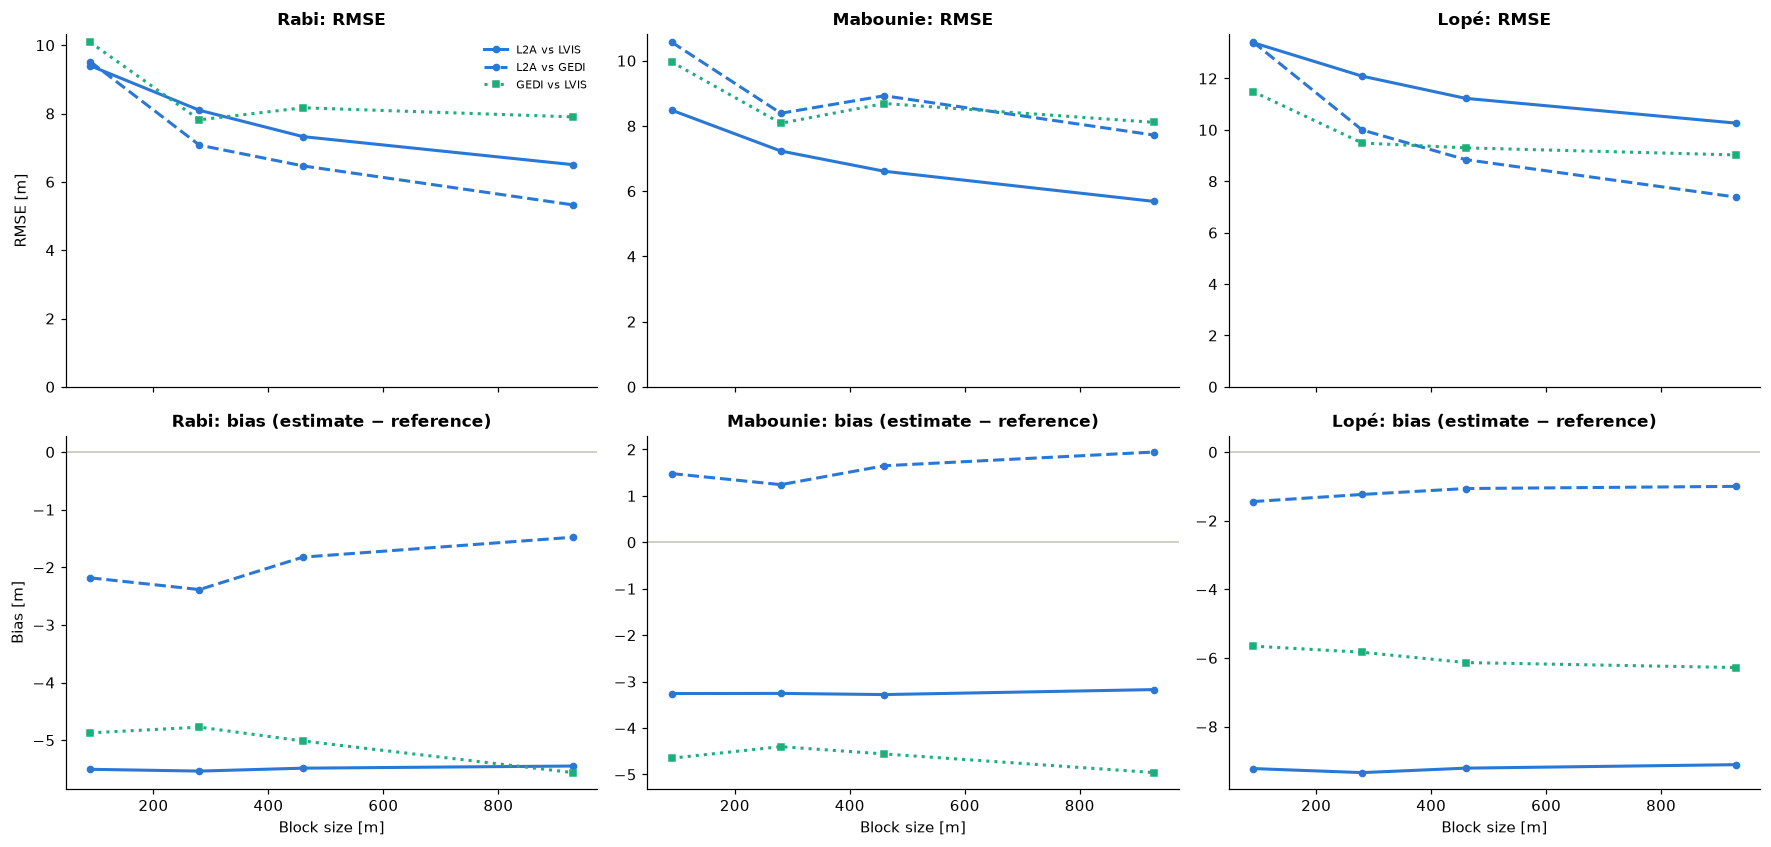

bias                     rmse                    
size_m              90          930          90            930      
reference          LVIS  GEDI  LVIS  GEDI   LVIS   GEDI   LVIS  GEDI
site     estimate                                                   
Rabi     L2A      -5.50 -2.18 -5.45 -1.48   9.40   9.52   6.50  5.33
Mabounie L2A      -3.26  1.48 -3.17  1.94   8.48  10.57   5.68  7.72
Lopé     L2A      -9.22 -1.44 -9.11 -1.00  13.40  13.42  10.26  7.39

In [14]:
fig, ax = plt.subplots(2, len(KEYS), figsize=(5.4 * len(KEYS), 7.8), sharex=True, squeeze=False)
for j, k in enumerate(KEYS):
    t = BC[(BC.site == D[k]["name"]) & (BC.area == "LiDAR area")]
    for name in PROD:
        for ref, ls in (("LVIS", "-"), ("GEDI", "--")):
            u = t[(t.estimate == name) & (t.reference == ref)].sort_values("size_m")
            ax[0, j].plot(u.size_m, u.rmse, ls=ls, marker="o", ms=4, color=PRODUCTS[name], lw=2, label=f"{name} vs {ref}")
            ax[1, j].plot(u.size_m, u.bias, ls=ls, marker="o", ms=4, color=PRODUCTS[name], lw=2, label=f"{name} vs {ref}")
    u = t[t.estimate == "GEDI (all shots)"].sort_values("size_m")
    ax[0, j].plot(u.size_m, u.rmse, ls=":", marker="s", ms=4, color=C_GEDI, lw=2, label="GEDI vs LVIS")
    ax[1, j].plot(u.size_m, u.bias, ls=":", marker="s", ms=4, color=C_GEDI, lw=2, label="GEDI vs LVIS")
    ax[0, j].set_title(f"{D[k]['name']}: RMSE"); ax[1, j].set_title(f"{D[k]['name']}: bias (estimate − reference)")
    ax[0, j].set_ylim(0, None); ax[1, j].axhline(0, color="#c3c2b7", lw=1); ax[1, j].set_xlabel("Block size [m]")
ax[0, 0].set_ylabel("RMSE [m]"); ax[1, 0].set_ylabel("Bias [m]"); ax[0, 0].legend(frameon=False, fontsize=7.5)
fig.tight_layout(); savefig(fig, "09_gedi_vs_lvis_referee"); plt.show()

t = BC[(BC.area == "LiDAR area") & BC.estimate.isin(list(PROD)) & BC.k.isin([1, BC.k.max()])]
display(t.pivot_table(index=["site", "estimate"], columns=["size_m", "reference"], values=["bias", "rmse"], sort=False).round(2))

**How to read it.**
- **Bias:** if a product is almost unbiased against GEDI but several metres too low against LVIS, the difference is GEDI's own
  low bias (dotted line). "Unbiased against GEDI" does **not** mean an unbiased product.
- **RMSE against GEDI is expected to be higher than against LVIS**, because GEDI adds its own noise. Even a perfect map could not get below the dotted line.
- **Ranking.** Compare the products with both referees: in the original run the ranking of the two BIOMASS products was the same with either referee once the data were aggregated.
- If you added an external map trained on GEDI, its agreement with GEDI is partly circular: trust the LVIS columns more.

### 9c — Beyond the LiDAR strips

GEDI covers the whole site box, not only the LVIS strips. If the numbers outside the strips are similar, our conclusions are not a peculiarity of the few kilometres flown by the aircraft.

In [15]:
t = BC[(BC.reference == "GEDI") & BC.estimate.isin(list(PROD)) & BC.k.isin([5, BC.k.max()])]
display(t.pivot_table(index=["site", "estimate", "size_m"], columns="area", values=["n", "bias", "rmse"], sort=False).round(2))

n                     bias                \
area                     LiDAR area outside LiDAR LiDAR area outside LiDAR   
site     estimate size_m                                                     
Rabi     L2A      460         333.0        3246.0      -1.82         -2.84   
                  930         131.0        1156.0      -1.48         -2.17   
Mabounie L2A      460         708.0        2213.0       1.65          1.53   
                  930         256.0         739.0       1.94          2.36   
Lopé     L2A      460        1392.0        6151.0      -1.06         -4.52   
                  930         444.0        1800.0      -1.00         -4.28   

                               rmse                
area                     LiDAR area outside LiDAR  
site     estimate size_m                           
Rabi     L2A      460          6.47          7.28  
                  930          5.33          6.30  
Mabounie L2A      460          8.92          9.33  
                  930          7.72          9.89  
Lopé     L2A      460          8.84         10.01  
                  930          7.39          8.10

Outside the strips there are **many more blocks**. If the errors there are of the same size as inside, the conclusions are not a peculiarity of the few kilometres flown by the aircraft. Where the bias changes between inside and outside, the landscape outside is different (more forest–savanna edges, steeper hills).

## 10 — Verdict

The numbers below are generated from the tables above.

In [16]:
L = []
w1 = SCALE[SCALE.window == 1].assign(noise=lambda t: 100 * t.sd ** 2 / t.rmse ** 2)
l2 = w1[w1["product"] == "L2A"].set_index("site")
L.append("Official L2A, forest pixels at 100 m, RMSE against LVIS: " + "; ".join(f"{s} {r.rmse:.1f} m (bias {r.bias:+.1f} m)" for s, r in l2.iterrows()) +
         f". Share of the squared error that is random noise: {l2.noise.min():.0f}–{l2.noise.max():.0f}%.")
if OTHER:
    big = SCALE.window.max()
    for n in OTHER:
        a = SCALE[(SCALE["product"] == n) & (SCALE.window == 1)].set_index("site")
        b = SCALE[(SCALE["product"] == n) & (SCALE.window == big)].set_index("site")
        c = SCALE[(SCALE["product"] == "L2A") & (SCALE.window == big)].set_index("site")
        L.append(f"{n} at 100 m: " + "; ".join(f"{s} RMSE {r.rmse:.1f} m (L2A {l2.loc[s, 'rmse']:.1f} m)" for s, r in a.iterrows()) +
                 f". Averaged over ≈{int(SCALE[SCALE.window == big].size_m.median())} m: " +
                 "; ".join(f"{s} {r.rmse:.1f} m (L2A {c.loc[s, 'rmse']:.1f} m)" for s, r in b.iterrows()) + ".")
if len(TERRAIN):
    for (site, orb), t in TERRAIN[TERRAIN["product"] == "L2A"].groupby(["site", "orbit"]):
        t = t.iloc[0]
        L.append(f"Slopes ({site}, {orb}), official L2A, extra error relative to radar-flat terrain: facing the radar "
                 f"{t['facing radar − flat [m]']:+.1f} m, facing away {t['facing away − flat [m]']:+.1f} m.")
sv = SV[SV.cover == "savanna"]
for site, t in sv.groupby("site"):
    t = t.set_index("product")
    if "L2A" in t.index and t.loc["L2A", "pixels"] >= 300:
        s_ = f"Savanna ({site}): LiDAR {t.loc['L2A', 'lvis_median']:.1f} m; official {t.loc['L2A', 'biomass_median']:.1f} m (recall {t.loc['L2A', 'recall']:.0f}%)"
        for n in OTHER:
            if n in t.index:
                s_ += f", {n} {t.loc[n, 'biomass_median']:.1f} m (recall {t.loc[n, 'recall']:.0f}%, {t.loc[n, 'pixels']:.0f} valid pixels)"
        L.append(s_ + ".")
if len(REP_SUM):
    r = REP_SUM[REP_SUM.geometry == "same direction"].set_index(["product", "scale"]).median_rmse
    L.append("Official L2A, two dates, same direction (median RMSE between dates): " + ", ".join(f"{s} {r[(p, s)]:.1f} m" for p, s in r.index) + ".")
if len(GEO):
    L.append("Geolocation: best-matching shift " + ", ".join(f"{g.site} {g['product']} {g['shift [m]']} m" for _, g in GEO.iterrows()) + " (one pixel ≈ 100 m).")
g1 = BC[(BC.estimate == "GEDI (all shots)") & (BC.k == 1)]
gb = BC[(BC.estimate == "GEDI (power beams, night)") & (BC.k == 1)]
L.append(f"GEDI as referee (forest pixels): GEDI − LVIS bias {g1.bias.min():+.1f} to {g1.bias.max():+.1f} m (power beams at night "
         f"{gb.bias.min():+.1f} to {gb.bias.max():+.1f} m), RMSE {g1.rmse.min():.1f}–{g1.rmse.max():.1f} m per pixel.")
a = BC[(BC.estimate == "L2A") & (BC.area == "LiDAR area") & (BC.k == 1)].pivot(index="site", columns="reference", values="bias")
L.append("Official L2A bias against GEDI " + ", ".join(f"{s} {r['GEDI']:+.1f} m" for s, r in a.iterrows()) +
         " but against LVIS " + ", ".join(f"{s} {r['LVIS']:+.1f} m" for s, r in a.iterrows()) +
         ": GEDI's own low bias hides part of the underestimation of BIOMASS.")
VERDICT = L
display(Markdown("\n".join(f"{i}. {l}" for i, l in enumerate(L, 1))))

1. Official L2A, forest pixels at 100 m, RMSE against LVIS: Rabi 9.4 m (bias -5.5 m); Mabounie 8.5 m (bias -3.3 m); Lopé 13.4 m (bias -9.2 m). Share of the squared error that is random noise: 53–85%.
2. Slopes (Lopé, ascending), official L2A, extra error relative to radar-flat terrain: facing the radar -8.8 m, facing away +2.9 m.
3. Slopes (Mabounie, ascending), official L2A, extra error relative to radar-flat terrain: facing the radar -5.6 m, facing away +3.6 m.
4. Slopes (Mabounie, descending), official L2A, extra error relative to radar-flat terrain: facing the radar -6.9 m, facing away -1.8 m.
5. Slopes (Rabi, ascending), official L2A, extra error relative to radar-flat terrain: facing the radar -6.9 m, facing away +nan m.
6. Slopes (Rabi, descending), official L2A, extra error relative to radar-flat terrain: facing the radar -4.7 m, facing away +0.8 m.
7. Savanna (Lopé): LiDAR 3.5 m; official 21.4 m (recall 5%).
8. Savanna (Mabounie): LiDAR 2.6 m; official 9.2 m (recall 54%).
9. Official L2A, two dates, same direction (median RMSE between dates): 100 m 12.0 m, 500 m 10.0 m.
10. Geolocation: best-matching shift Rabi L2A 290 m, Mabounie L2A 210 m, Lopé L2A 130 m (one pixel ≈ 100 m).
11. GEDI as referee (forest pixels): GEDI − LVIS bias -5.7 to -4.7 m (power beams at night -3.8 to -2.0 m), RMSE 10.0–11.5 m per pixel.
12. Official L2A bias against GEDI Lopé -1.4 m, Mabounie +1.5 m, Rabi -2.2 m but against LVIS Lopé -9.2 m, Mabounie -3.3 m, Rabi -5.5 m: GEDI's own low bias hides part of the underestimation of BIOMASS.

**What it means.**
- Read the numbers above together with the caveats: LVIS is from 2016, BIOMASS from 2026, GEDI from 2019–2025, and an external map from its own year, so some differences are forest change, not error.
- **GEDI is a good referee for averages over many shots, a noisy one for single pixels, and it sits a few metres low**: everything compared with it inherits this.
- **Scale matters.** Compare products at the scale you need (100 m map, or averages over a few hundred metres to ≈ 1 km).
- Notebook 02 in its original form also compares a second BIOMASS product (workshop FH) per date. That part needs the workshop files; this variant does not reproduce it.

## 11 — Automatic report

The cell below builds a short slide deck from the figures and numbers of this notebook: results/L2A_vs_GEDI_LVIS_no_workshop.pptx.

In [17]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from PIL import Image

INK, MUTED, ACCENT = RGBColor(0x0B, 0x0B, 0x0B), RGBColor(0x52, 0x51, 0x4E), RGBColor(0xC2, 0x45, 0x7A)
prs = Presentation(); prs.slide_width, prs.slide_height = Inches(13.333), Inches(7.5); BLANK = prs.slide_layouts[6]

def textbox(slide, x, y, w, h, paras, size=16, color=INK, bold_first=False):
    tf = slide.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)).text_frame; tf.word_wrap = True
    for i, t in enumerate(paras):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = t; p.font.size = Pt(size); p.font.color.rgb = color; p.font.bold = bold_first and i == 0; p.space_after = Pt(8)

def header(slide, title, kicker=None):
    bar = slide.shapes.add_shape(1, 0, 0, prs.slide_width, Inches(0.12)); bar.fill.solid(); bar.fill.fore_color.rgb = ACCENT; bar.line.fill.background()
    textbox(slide, 0.5, 0.3, 12.3, 0.8, [title], size=28, bold_first=True)
    if kicker: textbox(slide, 0.5, 0.95, 12.3, 0.5, [kicker], size=14, color=MUTED)

def picture(slide, path, x, y, mw, mh):
    w, h = Image.open(path).size; s = min(mw / w, mh / h)
    slide.shapes.add_picture(str(path), Inches(x + (mw - w * s) / 2), Inches(y + (mh - h * s) / 2), Inches(w * s), Inches(h * s))

def fig_slide(title, kicker, key, bullets, full=True):
    if key not in FIGS: return
    s = prs.slides.add_slide(BLANK); header(s, title, kicker)
    if full:
        picture(s, FIGS[key], 0.4, 1.55, 12.5, 4.6); textbox(s, 0.6, 6.25, 12, 1.1, bullets, size=14)
    else:
        picture(s, FIGS[key], 0.4, 1.55, 8.6, 5.6); textbox(s, 9.2, 1.7, 3.8, 5.4, bullets, size=15)

s = prs.slides.add_slide(BLANK)
bg = s.shapes.add_shape(1, 0, 0, prs.slide_width, prs.slide_height); bg.fill.solid(); bg.fill.fore_color.rgb = RGBColor(0x3B, 0x10, 0x25); bg.line.fill.background()
textbox(s, .8, 2.2, 11.5, 1.2, ["BIOMASS forest height against GEDI and LVIS"], size=40, color=RGBColor(255, 255, 255), bold_first=True)
textbox(s, .8, 3.5, 11.5, 1.5, ["Official L2A forest height against GEDI and NASA LVIS LiDAR at Rabi, Mabounie and Lopé (Gabon)",
                                "ESA MAAP Hackathon 2026 — Challenge #5 — generated automatically by the notebook"], size=18, color=RGBColor(0xF3, 0xDD, 0xE7))
fig_slide("Same forest, same scale", "Same colour scale, same window", "02_first_look", ["LiDAR, official L2A and (if provided) the external map"], full=False)
fig_slide("Height distributions", "Forest height distributions under the LiDAR", "03_histograms",
          ["Compare the width of each distribution with the LiDAR one"])
fig_slide("Pixel by pixel", "RMSE against LVIS at 100 m, by landscape stratum", "04_rmse_by_stratum", VERDICT[:1])
fig_slide("Noise or bias? The averaging test", "Product and LiDAR averaged over larger windows", "05_error_vs_scale", VERDICT[1:3])
fig_slide("Slopes facing the radar", "Official L2A forest error vs local incidence angle", "06_error_vs_lia",
          [l for l in VERDICT if l.startswith("Slopes")][:3])
fig_slide("Is GEDI a good referee?", "GEDI − LVIS in forest pixels", "08_gedi_vs_lvis", [l for l in VERDICT if l.startswith("GEDI as referee")][:1])
fig_slide("BIOMASS against GEDI and against LVIS", "Solid: vs LVIS, dashed: vs GEDI, dotted: GEDI vs LVIS", "09_gedi_vs_lvis_referee",
          [l for l in VERDICT if l.startswith("Official L2A bias") or l.startswith("Against GEDI")][:2])
s = prs.slides.add_slide(BLANK); header(s, "Verdict", "Generated from the notebook results")
textbox(s, .6, 1.5, 12.1, 5.9, [f"{i}. {l}" for i, l in enumerate(VERDICT, 1)], size=11)
report = ROOT / "results" / "L2A_vs_GEDI_LVIS_no_workshop.pptx"; prs.save(report)
print("Report:", report, f"({len(prs.slides)} slides)")

Report: /home/alexia/biomass2026/biomass-hackathon-2026/topics/05_BIOMASS_AND_GEDI/forestheight/results/L2A_vs_GEDI_LVIS_no_workshop.pptx (9 slides)
